<div align="center">

<h1><strong>PEMBUATAN PROMPTING STUDI KASUS GEOFISIKA</strong></h1>
<h2><strong>KECERDASAN ARTIFISIAL UNTUK GEOFISIKA</strong></h2>


<img src="https://www.unhas.ac.id/wp-content/uploads/2022/09/Logo-Resmi-Unhas-1.png" 
     alt="Logo Universitas Hasanuddin" 
     style="width:250px; margin:20px 0;">

<h5><strong> Oleh:</strong></h5>
<ul style="list-style:none; padding-left:0; line-height:1.8; width:400px;">
  <li>
    <strong>MUHAMMAD IRFAN</strong>
    <div style="margin-top:10px;">
      <strong>H061241002</strong>
    </div>
  </li>
</ul>

<p><strong>DEPARTEMEN GEOFISIKA</strong></p>
<p><strong>FAKULTAS MATEMATIKA DAN ILMU PENGETAHUAN ALAM</strong></p>
<p><strong></strong></p>
<p><strong></strong></p>
<p><strong>2026</strong></p>

</div>

# **1. STUDI KASUS ERT UNTUK IDENTIFIKASI AKUIFER**

### **Role**

Anda berperan sebagai seorang **Geophysicist Exploration** yang memiliki kompetensi dalam metode geolistrik, khususnya **Electrical Resistivity Tomography (ERT)**, pengolahan data resistivitas, interpretasi kondisi bawah permukaan, serta penerapan metode geofisika untuk eksplorasi air tanah. Anda memiliki kemampuan untuk menghubungkan nilai resistivitas dengan kondisi geologi, jenis material bawah permukaan, porositas, dan tingkat kejenuhan air.

### **Task**

Lakukan analisis terhadap data ERT untuk mengidentifikasi kondisi bawah permukaan dan menentukan zona yang berpotensi sebagai akuifer. Analisis harus mencakup interpretasi distribusi resistivitas terhadap jarak dan kedalaman, korelasi antara nilai resistivitas dengan kemungkinan litologi, serta evaluasi faktor-faktor yang dapat memengaruhi interpretasi. Tentukan zona yang paling memungkinkan mengandung air tanah berdasarkan integrasi antara data geofisika dan informasi geologi yang tersedia.

### **Context**

Survei ERT dilakukan pada suatu daerah yang mengalami keterbatasan sumber air bersih. Masyarakat setempat membutuhkan informasi mengenai kondisi bawah permukaan untuk menentukan lokasi yang sesuai untuk pengembangan sumber air tanah. Pengukuran dilakukan menggunakan konfigurasi Wenner Alpha dengan spasi elektroda yang konstan, kemudian data apparent resistivity diproses menggunakan metode inversi 2D untuk memperoleh penampang distribusi resistivitas bawah permukaan. Hasil inversi tersebut akan digunakan sebagai dasar untuk memperkirakan keberadaan lapisan pembawa air.

### **Input**

Data yang diberikan berupa koordinat dan posisi elektroda, spasi elektroda sebesar 5 meter, konfigurasi Wenner Alpha, data apparent resistivity, penampang hasil inversi resistivitas 2D, nilai RMS error atau RRMS, serta informasi geologi permukaan daerah penelitian. Apabila tersedia, data tambahan berupa informasi muka air tanah, data sumur, dan informasi litologi dapat digunakan sebagai kontrol interpretasi. Gunakan hanya data yang tersedia dan jangan membuat nilai atau informasi tambahan yang tidak diberikan.

### **Constraints**

Dalam melakukan interpretasi, jangan menentukan suatu zona sebagai akuifer hanya berdasarkan nilai resistivitas rendah karena material lempung atau material tertentu juga dapat menghasilkan resistivitas rendah. Interpretasi harus mempertimbangkan hubungan antara resistivitas, litologi, porositas, kandungan air, dan kondisi geologi. Bedakan dengan jelas antara data pengukuran, hasil inversi, interpretasi, dan asumsi. Jangan membuat data yang tidak tersedia serta jelaskan ketidakpastian yang dapat memengaruhi hasil interpretasi.

### **Output**

Sajikan hasil analisis secara sistematis dengan menjelaskan prinsip dasar metode ERT, kualitas data, karakteristik penampang resistivitas, hubungan nilai resistivitas dengan kemungkinan litologi, identifikasi zona potensial akuifer, perkiraan kedalaman zona akuifer jika memungkinkan, faktor ketidakpastian, serta kesimpulan dan rekomendasi untuk investigasi lanjutan. Gunakan bahasa akademik yang jelas dan terminologi geofisika yang tepat.



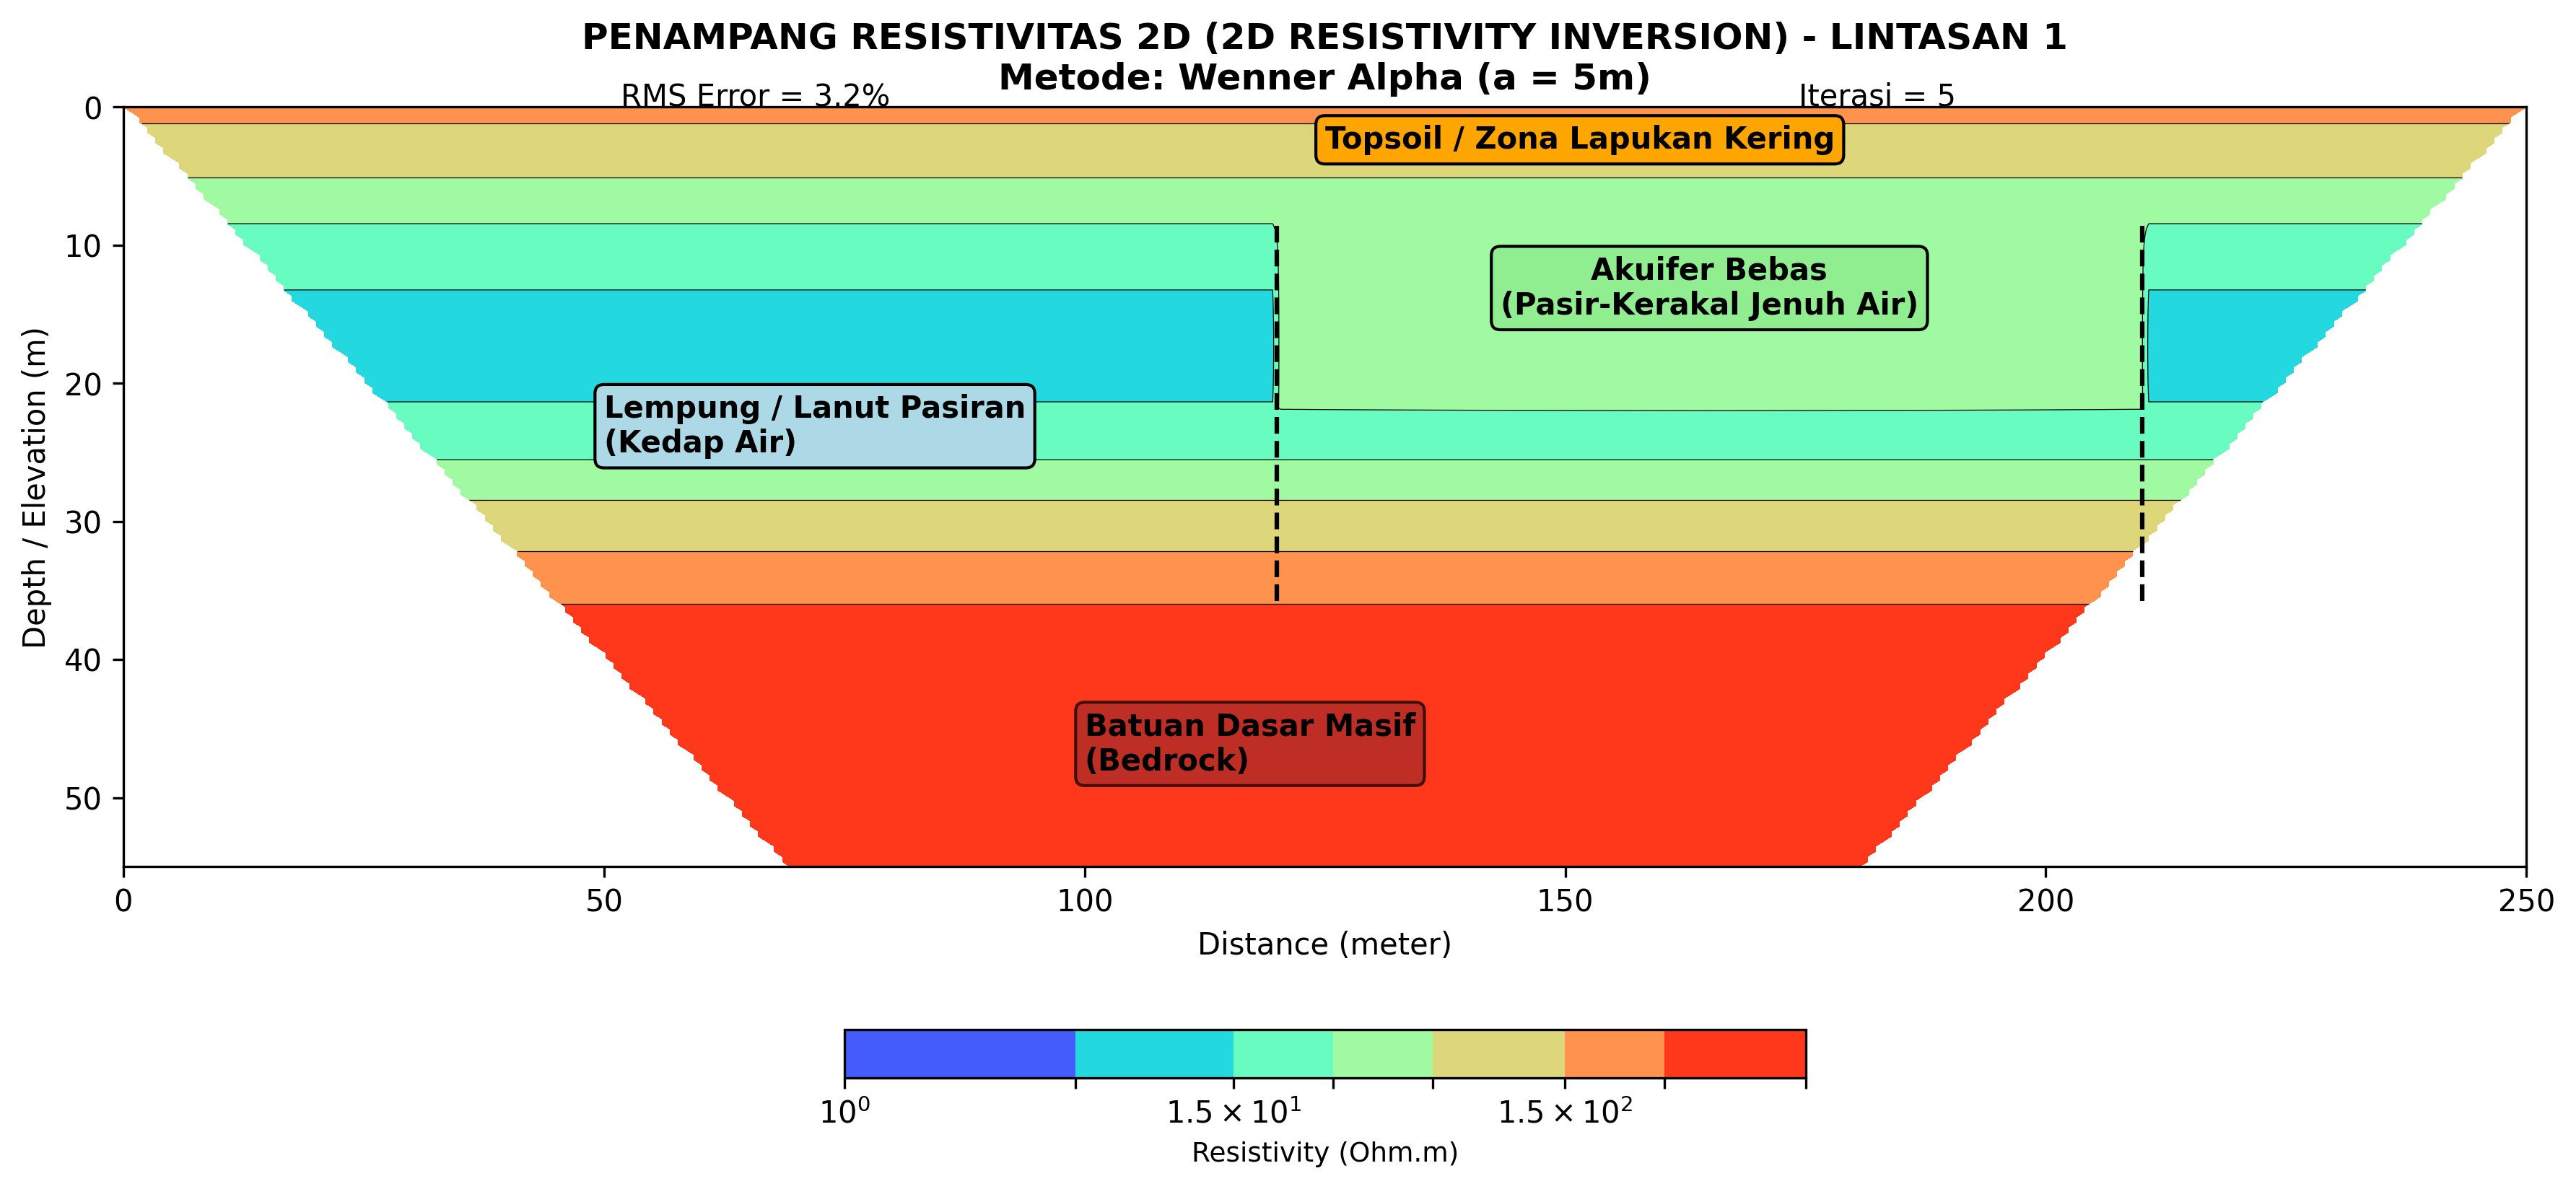

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

# 1. Bikin grid data sintetis (Jarak 0 - 250m, Kedalaman 0 - 55m)
x = np.linspace(0, 250, 300)
z = np.linspace(0, 55, 150)
X, Z = np.meshgrid(x, z)

# 2. Bikin pemodelan nilai resistivitas (Ohm.m)
# Topsoil (Dangkal, nilai tinggi)
resistivity = 200 * np.exp(-Z / 4) 

# Batuan dasar / Bedrock (Sangat dalam, nilai tinggi)
resistivity += 500 * (1 / (1 + np.exp(-(Z - 35) / 3)))

# Lapisan lempung/lanut (Latar belakang nilai rendah ~10 Ohm.m)
resistivity += 10 * (1 - np.exp(-Z / 10))

# Anomali Akuifer (Zona Pasir-Kerakal: 20 - 50 Ohm.m pada bentang 120-210m, kedalaman 8-22m)
aquifer_mask = ((X >= 120) & (X <= 210) & (Z >= 8) & (Z <= 22))
resistivity[aquifer_mask] = 35 + 10 * np.sin((X[aquifer_mask]-120)/90 * np.pi)

# Masking bentuk trapezoid khas penampang inversi 2D
trapezoid_mask = (Z > (X * 0.8)) | (Z > ((250 - X) * 0.8))
resistivity = np.ma.masked_array(resistivity, mask=trapezoid_mask)

# 3. Visualisasi Plots
plt.figure(figsize=(12, 6), dpi=300)
cmap = plt.cm.rainbow

# Contouring dengan skala logaritmik
levels = [1, 5, 15, 30, 60, 150, 300, 800]
CS = plt.contourf(X, Z, resistivity, levels=levels, cmap=cmap, norm=LogNorm(vmin=1, vmax=800))
plt.contour(X, Z, resistivity, levels=levels, colors='black', linewidths=0.3)

# 4. Annotasi Zona & Teks Laporan
plt.text(125, 3, 'Topsoil / Zona Lapukan Kering', fontsize=10, fontweight='bold', bbox=dict(boxstyle="round,pad=0.3", fc="orange", ec="black", lw=1))
plt.text(50, 25, 'Lempung / Lanut Pasiran\n(Kedap Air)', fontsize=10, fontweight='bold', bbox=dict(boxstyle="round,pad=0.3", fc="lightblue", ec="black", lw=1))
plt.text(165, 15, 'Akuifer Bebas\n(Pasir-Kerakal Jenuh Air)', fontsize=10, fontweight='bold', ha='center', bbox=dict(boxstyle="round,pad=0.3", fc="lightgreen", ec="black", lw=1))
plt.text(100, 48, 'Batuan Dasar Masif\n(Bedrock)', fontsize=10, fontweight='bold', bbox=dict(boxstyle="round,pad=0.3", fc="brown", ec="black", lw=1, alpha=0.7))

# Garis batas zona akuifer
plt.axvline(x=120, ymin=0.35, ymax=0.85, color='black', linestyle='--')
plt.axvline(x=210, ymin=0.35, ymax=0.85, color='black', linestyle='--')

# 5. Format Judul & Sumbu
plt.title('PENAMPANG RESISTIVITAS 2D (2D RESISTIVITY INVERSION) - LINTASAN 1\nMetode: Wenner Alpha (a = 5m)', fontsize=12, fontweight='bold')
plt.suptitle('RMS Error = 3.2%                                                                                               Iterasi = 5', fontsize=10, y=0.88)
plt.xlabel('Distance (meter)', fontsize=10)
plt.ylabel('Depth / Elevation (m)', fontsize=10)
plt.gca().invert_yaxis()  # Membalik sumbu Y agar kedalaman mengarah ke bawah

# Colorbar
cbar = plt.colorbar(CS, orientation='horizontal', pad=0.15, shrink=0.4, aspect=20)
cbar.set_label('Resistivity (Ohm.m)', fontsize=9)

plt.tight_layout()
plt.savefig('penampang_ert_2d.png', dpi=300)
plt.show()

# **2. STUDI KASUS INTEGRASI SEISMIK DAN WELL LOG UNTUK RESERVOIR HIDROKARBON**

### **Role**

Anda berperan sebagai seorang **Exploration Geophysicist senior** yang memiliki keahlian dalam interpretasi seismic reflection, well logging, petrofisika, dan karakterisasi reservoir hidrokarbon. Anda memahami hubungan antara parameter fisik batuan seperti densitas, kecepatan gelombang P, porositas, resistivitas, dan kandungan fluida dengan respon data seismik dan well log.

### **Task**

Lakukan integrasi antara data seismic dan well log untuk mengidentifikasi serta mengkarakterisasi zona reservoir hidrokarbon. Analisis harus bertujuan untuk mengetahui karakteristik reservoir berdasarkan parameter petrofisika, menghubungkan informasi sumur dengan reflektor seismik, serta memperkirakan persebaran reservoir secara lateral dan vertikal. Evaluasi pula apakah karakteristik yang diperoleh memberikan indikasi yang konsisten dengan keberadaan hidrokarbon.

### **Context**

Sebuah lapangan eksplorasi migas memiliki data seismic 3D dan beberapa sumur eksplorasi. Beberapa interval sumur menunjukkan perubahan nilai Gamma Ray, resistivitas, densitas, neutron porosity, dan sonic yang mengindikasikan adanya perubahan litologi dan kemungkinan zona reservoir. Data seismik digunakan untuk mengetahui kontinuitas reflektor dan struktur bawah permukaan, sedangkan data well log digunakan sebagai kontrol langsung pada lokasi sumur. Integrasi kedua jenis data diperlukan untuk memperoleh interpretasi reservoir yang lebih komprehensif.

### **Input**

Data yang tersedia meliputi seismic 3D, Gamma Ray log, resistivity log, density log, neutron porosity log, sonic log, well tops, koordinat dan kedalaman sumur, serta data checkshot atau VSP apabila tersedia. Informasi tambahan seperti litologi, hasil analisis petrofisika, dan data marker formasi juga dapat digunakan sebagai kontrol interpretasi. Seluruh analisis harus menggunakan data yang tersedia dan tidak boleh mengasumsikan parameter yang tidak diberikan.

### **Constraints**

Jangan menentukan keberadaan hidrokarbon hanya berdasarkan satu parameter well log atau satu respon seismik. Interpretasi harus dilakukan dengan mengintegrasikan informasi seismic, well log, petrofisika, dan kondisi geologi. Bedakan antara indikasi hidrokarbon dan bukti langsung keberadaan hidrokarbon. Pertimbangkan keterbatasan resolusi vertikal seismik, jumlah sumur, kualitas data, serta ketidakpastian korelasi antara data sumur dan data seismik. Jangan membuat nilai atau informasi yang tidak terdapat dalam input.

### **Output**

Hasil akhir harus mencakup penjelasan mengenai karakteristik data, analisis well log, interpretasi seismic, korelasi well-to-seismic, identifikasi zona reservoir, karakterisasi sifat reservoir, interpretasi persebaran reservoir, evaluasi indikasi hidrokarbon, pembahasan ketidakpastian, serta kesimpulan dan rekomendasi penelitian lanjutan. Susun hasil secara logis dengan menggunakan terminologi geofisika eksplorasi dan petrofisika yang tepat.







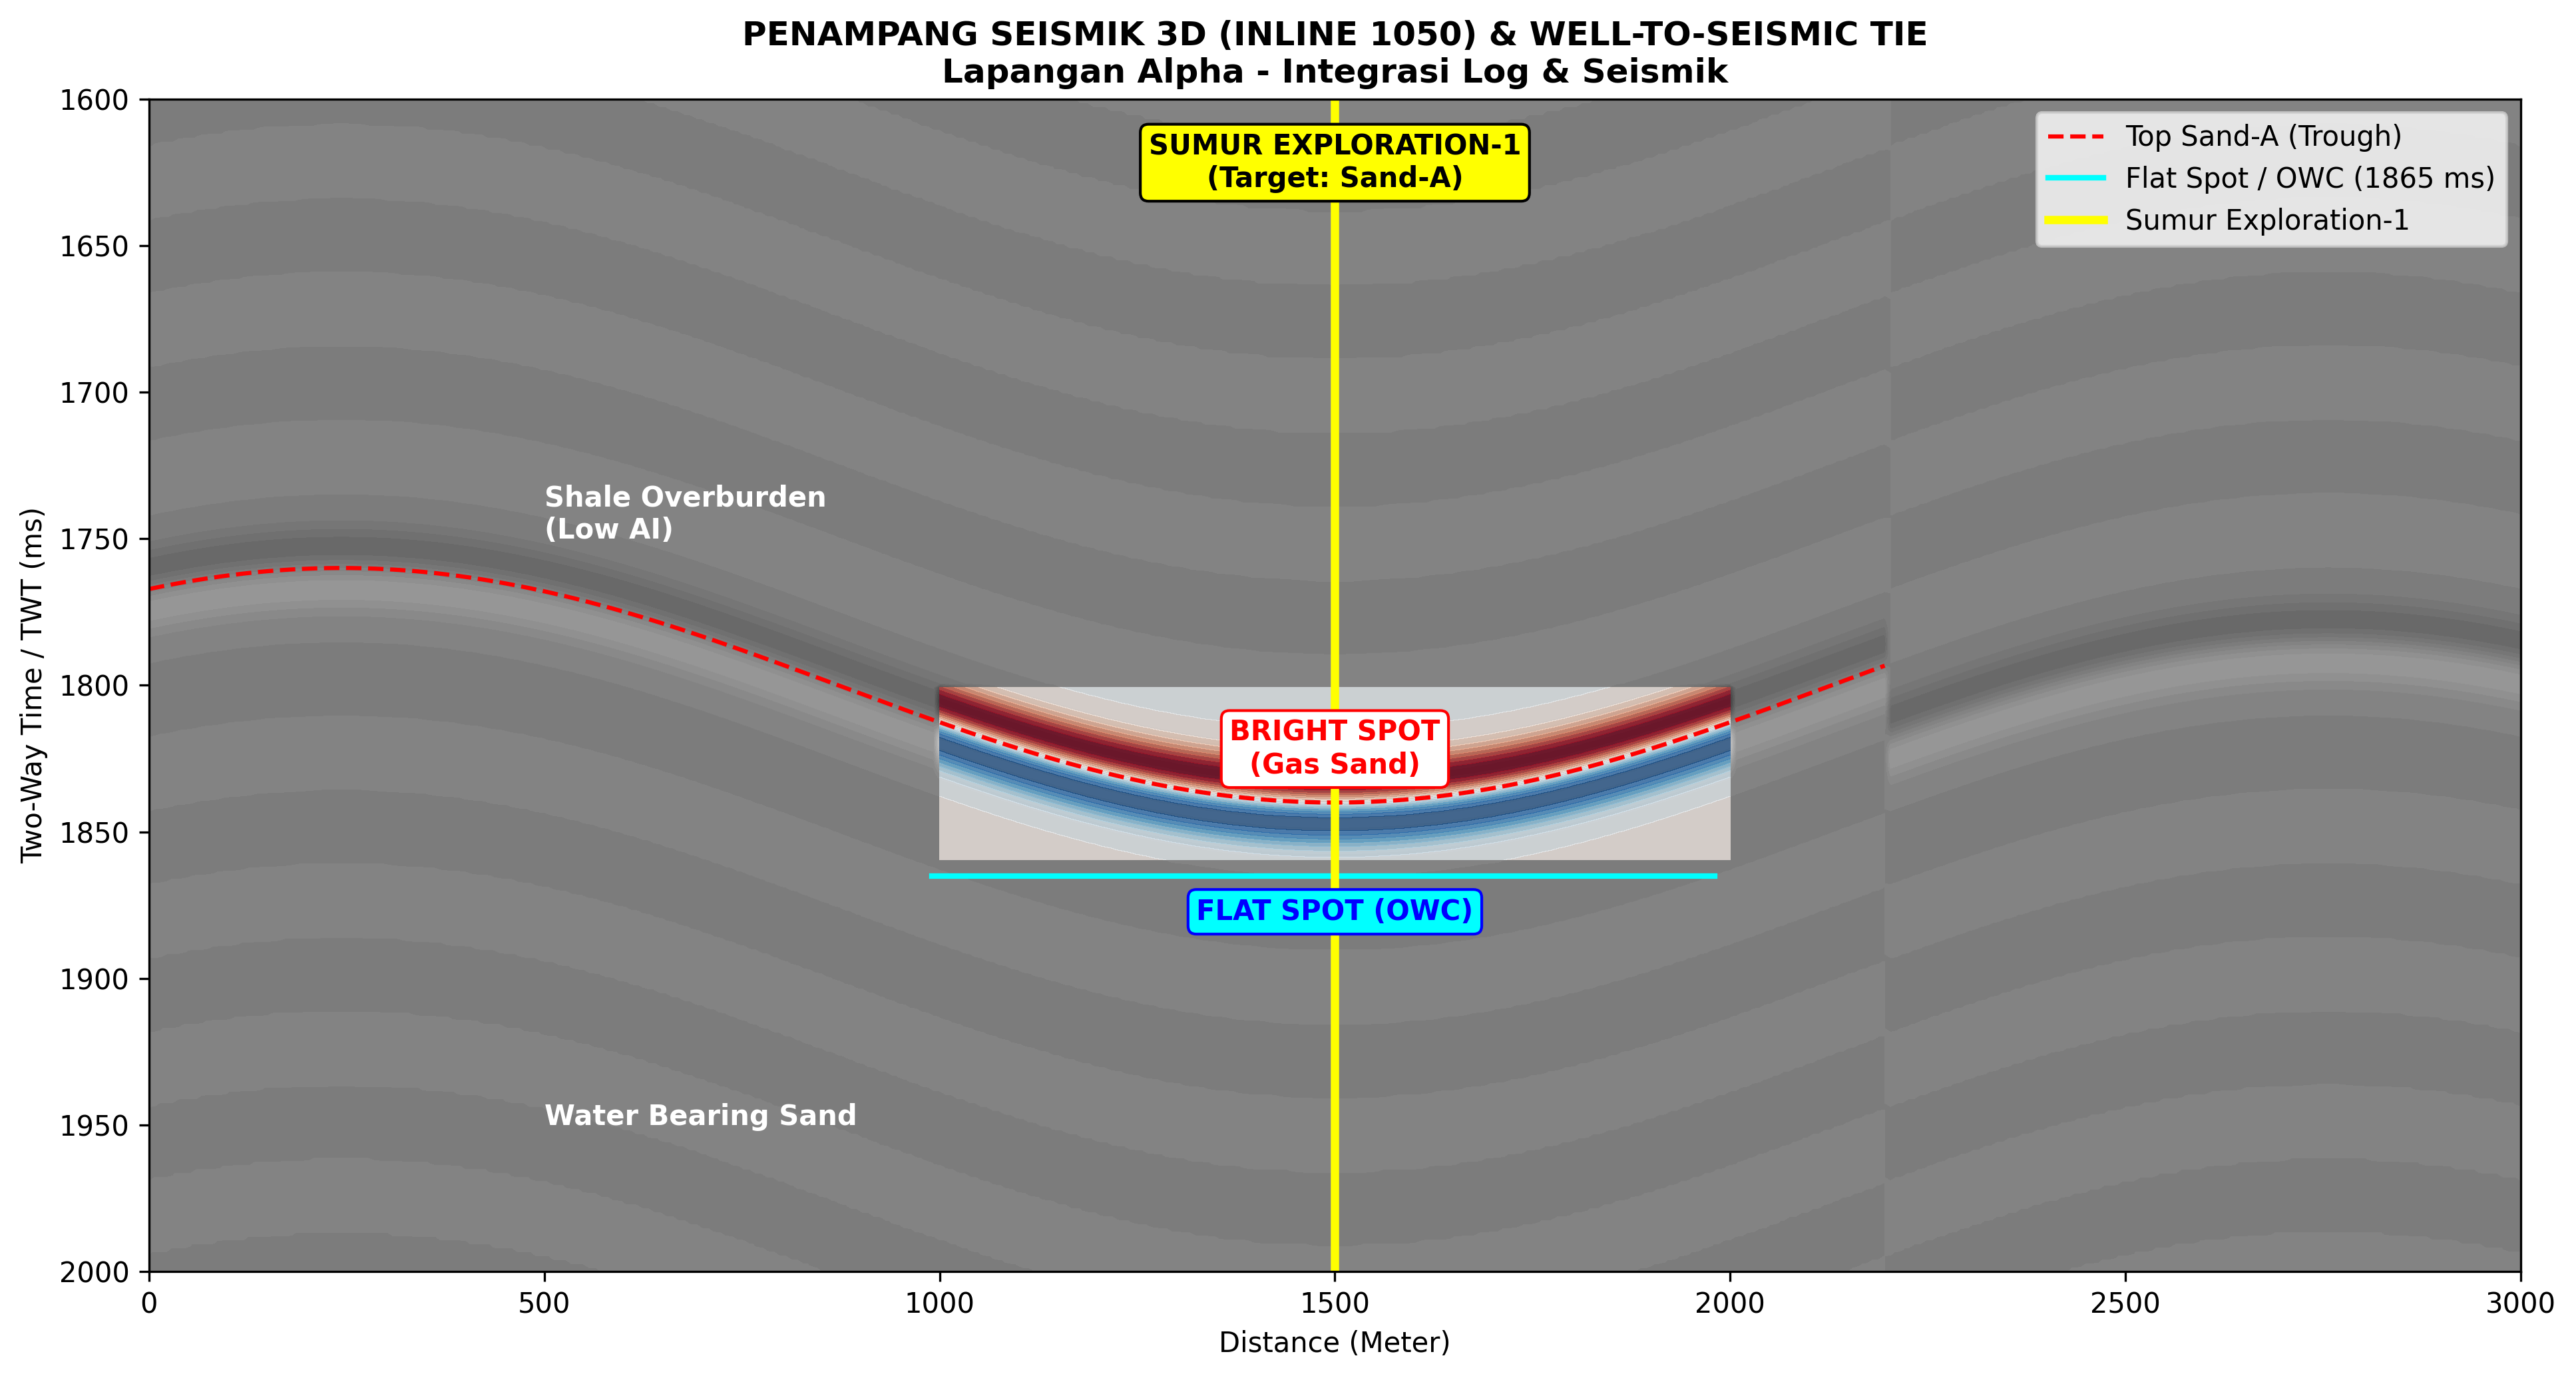

In [10]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Bikin Grid Seismik Sintetis
x = np.linspace(0, 3000, 400)          # Jarak lateral (400 titik)
t = np.linspace(1600, 2000, 300)       # Waktu TWT (300 titik)
X, T = np.meshgrid(x, t)

# 2. Pemodelan Struktur Antiklin + Sesar
# Menggunakan X (400 kolom) agar dimensi top_sand sesuai dengan x (400 elemen)
structure = 1800 + 40 * np.cos((x - 1500) / 400) 
fault = np.where(x > 2200, 25, 0)                
top_sand = structure + fault

# Respon Amplitudo Seismik (Menggunakan X dan T 2D)
top_sand_2d = 1800 + 40 * np.cos((X - 1500) / 400) + np.where(X > 2200, 25, 0)
seismic = np.sin((T - top_sand_2d) / 8) * np.exp(-((T - top_sand_2d)**2) / 150)

# Tambahkan Fitur DHI (Bright Spot pada Puncak Antiklin 1000m - 2000m)
bright_spot_mask = (X >= 1000) & (X <= 2000) & (T >= 1800) & (T <= 1860)
seismic[bright_spot_mask] *= 2.8  

# 3. Canvas Plots
fig, ax = plt.subplots(figsize=(13, 7), dpi=300)

# Plot Penampang Seismik
im = ax.contourf(X, T, seismic, levels=30, cmap='gray', vmin=-3, vmax=3)

# Overlay Anomali Bright Spot
ax.contourf(X, T, np.where(bright_spot_mask, seismic, np.nan), levels=15, cmap='RdBu', alpha=0.7)

# 4. Plot Horizon Top Sand & Base Sand (PERBAIKAN INDEXING DI SINI)
mask_x = x <= 2200
ax.plot(x[mask_x], top_sand[mask_x], 'r--', linewidth=1.5, label='Top Sand-A (Trough)')
ax.axhline(y=1865, xmin=0.33, xmax=0.66, color='cyan', linestyle='-', linewidth=2, label='Flat Spot / OWC (1865 ms)')

# Plot Sumur Exploration-1
ax.axvline(x=1500, color='yellow', linewidth=3, label='Sumur Exploration-1')

# Teks Annotasi
ax.text(1500, 1630, 'SUMUR EXPLORATION-1\n(Target: Sand-A)', color='black', fontweight='bold', ha='center', bbox=dict(boxstyle='round', fc='yellow', ec='black'))
ax.text(1500, 1830, 'BRIGHT SPOT\n(Gas Sand)', color='red', fontweight='bold', ha='center', bbox=dict(boxstyle='round', fc='white', ec='red'))
ax.text(1500, 1880, 'FLAT SPOT (OWC)', color='blue', fontweight='bold', ha='center', bbox=dict(boxstyle='round', fc='cyan', ec='blue'))
ax.text(500, 1750, 'Shale Overburden\n(Low AI)', color='white', fontweight='bold')
ax.text(500, 1950, 'Water Bearing Sand', color='white', fontweight='bold')

# Setup Sumbu
ax.set_title('PENAMPANG SEISMIK 3D (INLINE 1050) & WELL-TO-SEISMIC TIE\nLapangan Alpha - Integrasi Log & Seismik', fontsize=12, fontweight='bold')
ax.set_xlabel('Distance (Meter)', fontsize=10)
ax.set_ylabel('Two-Way Time / TWT (ms)', fontsize=10)
ax.invert_yaxis()
ax.legend(loc='upper right')

plt.tight_layout()
plt.savefig('integrasi_seismik_well_log.png', dpi=300)
plt.show()

# **3. STUDI KASUS MASW UNTUK KARAKTERISASI BAWAH PERMUKAAN**

### **Role**

Anda berperan sebagai seorang **Geophysicist** yang memiliki keahlian dalam metode **Multichannel Analysis of Surface Waves (MASW)**, analisis gelombang permukaan, interpretasi kurva dispersi, inversi kecepatan gelombang geser, dan karakterisasi kondisi bawah permukaan untuk kebutuhan geoteknik.

### **Task**

Lakukan analisis data MASW untuk memperoleh model kecepatan gelombang geser (Vs) terhadap kedalaman serta mengidentifikasi karakteristik lapisan bawah permukaan. Analisis harus mencakup interpretasi kurva dispersi, hubungan antara panjang gelombang dan kedalaman investigasi, proses inversi untuk mendapatkan model Vs, serta perhitungan Vs30 apabila data yang tersedia memungkinkan.

### **Context**

Survei MASW dilakukan pada suatu kawasan yang direncanakan untuk pembangunan infrastruktur. Informasi mengenai kondisi dan kekakuan material bawah permukaan diperlukan untuk mendukung evaluasi kondisi tanah. Akuisisi data dilakukan menggunakan beberapa geophone yang disusun dalam suatu array dengan sumber getaran pada posisi tertentu. Data hasil pengukuran kemudian digunakan untuk menghasilkan kurva dispersi dan model Vs bawah permukaan melalui proses inversi.

### **Input**

Data yang tersedia meliputi rekaman MASW, jumlah geophone sebanyak 24 unit, frekuensi geophone 4,5 Hz, jarak antar-geophone, posisi sumber, kurva dispersi, model Vs hasil inversi, serta informasi geologi permukaan apabila tersedia. Data tersebut digunakan untuk mengevaluasi variasi kecepatan gelombang geser terhadap kedalaman dan karakteristik lapisan bawah permukaan.

### **Constraints**

Jangan menganggap bahwa model Vs hasil inversi merupakan satu-satunya model bawah permukaan yang benar karena inversi geofisika memiliki sifat non-unique. Jelaskan kemungkinan ketidakpastian model dan hubungan antara kualitas kurva dispersi dengan hasil inversi. Jangan membuat nilai Vs atau parameter lain yang tidak tersedia. Jika data yang diberikan tidak cukup untuk menghitung Vs30 secara valid, nyatakan keterbatasan tersebut secara jelas dan jangan memberikan nilai yang dibuat-buat.

### **Output**

Sajikan hasil berupa penjelasan prinsip MASW, interpretasi kurva dispersi, hubungan frekuensi dan panjang gelombang dengan kedalaman investigasi, interpretasi model Vs, pembagian lapisan bawah permukaan berdasarkan nilai Vs, perhitungan Vs30 apabila memungkinkan, interpretasi kondisi material, ketidakpastian hasil inversi, serta kesimpulan. Gunakan bahasa akademik dan jelaskan hubungan antara setiap tahap analisis secara logis.



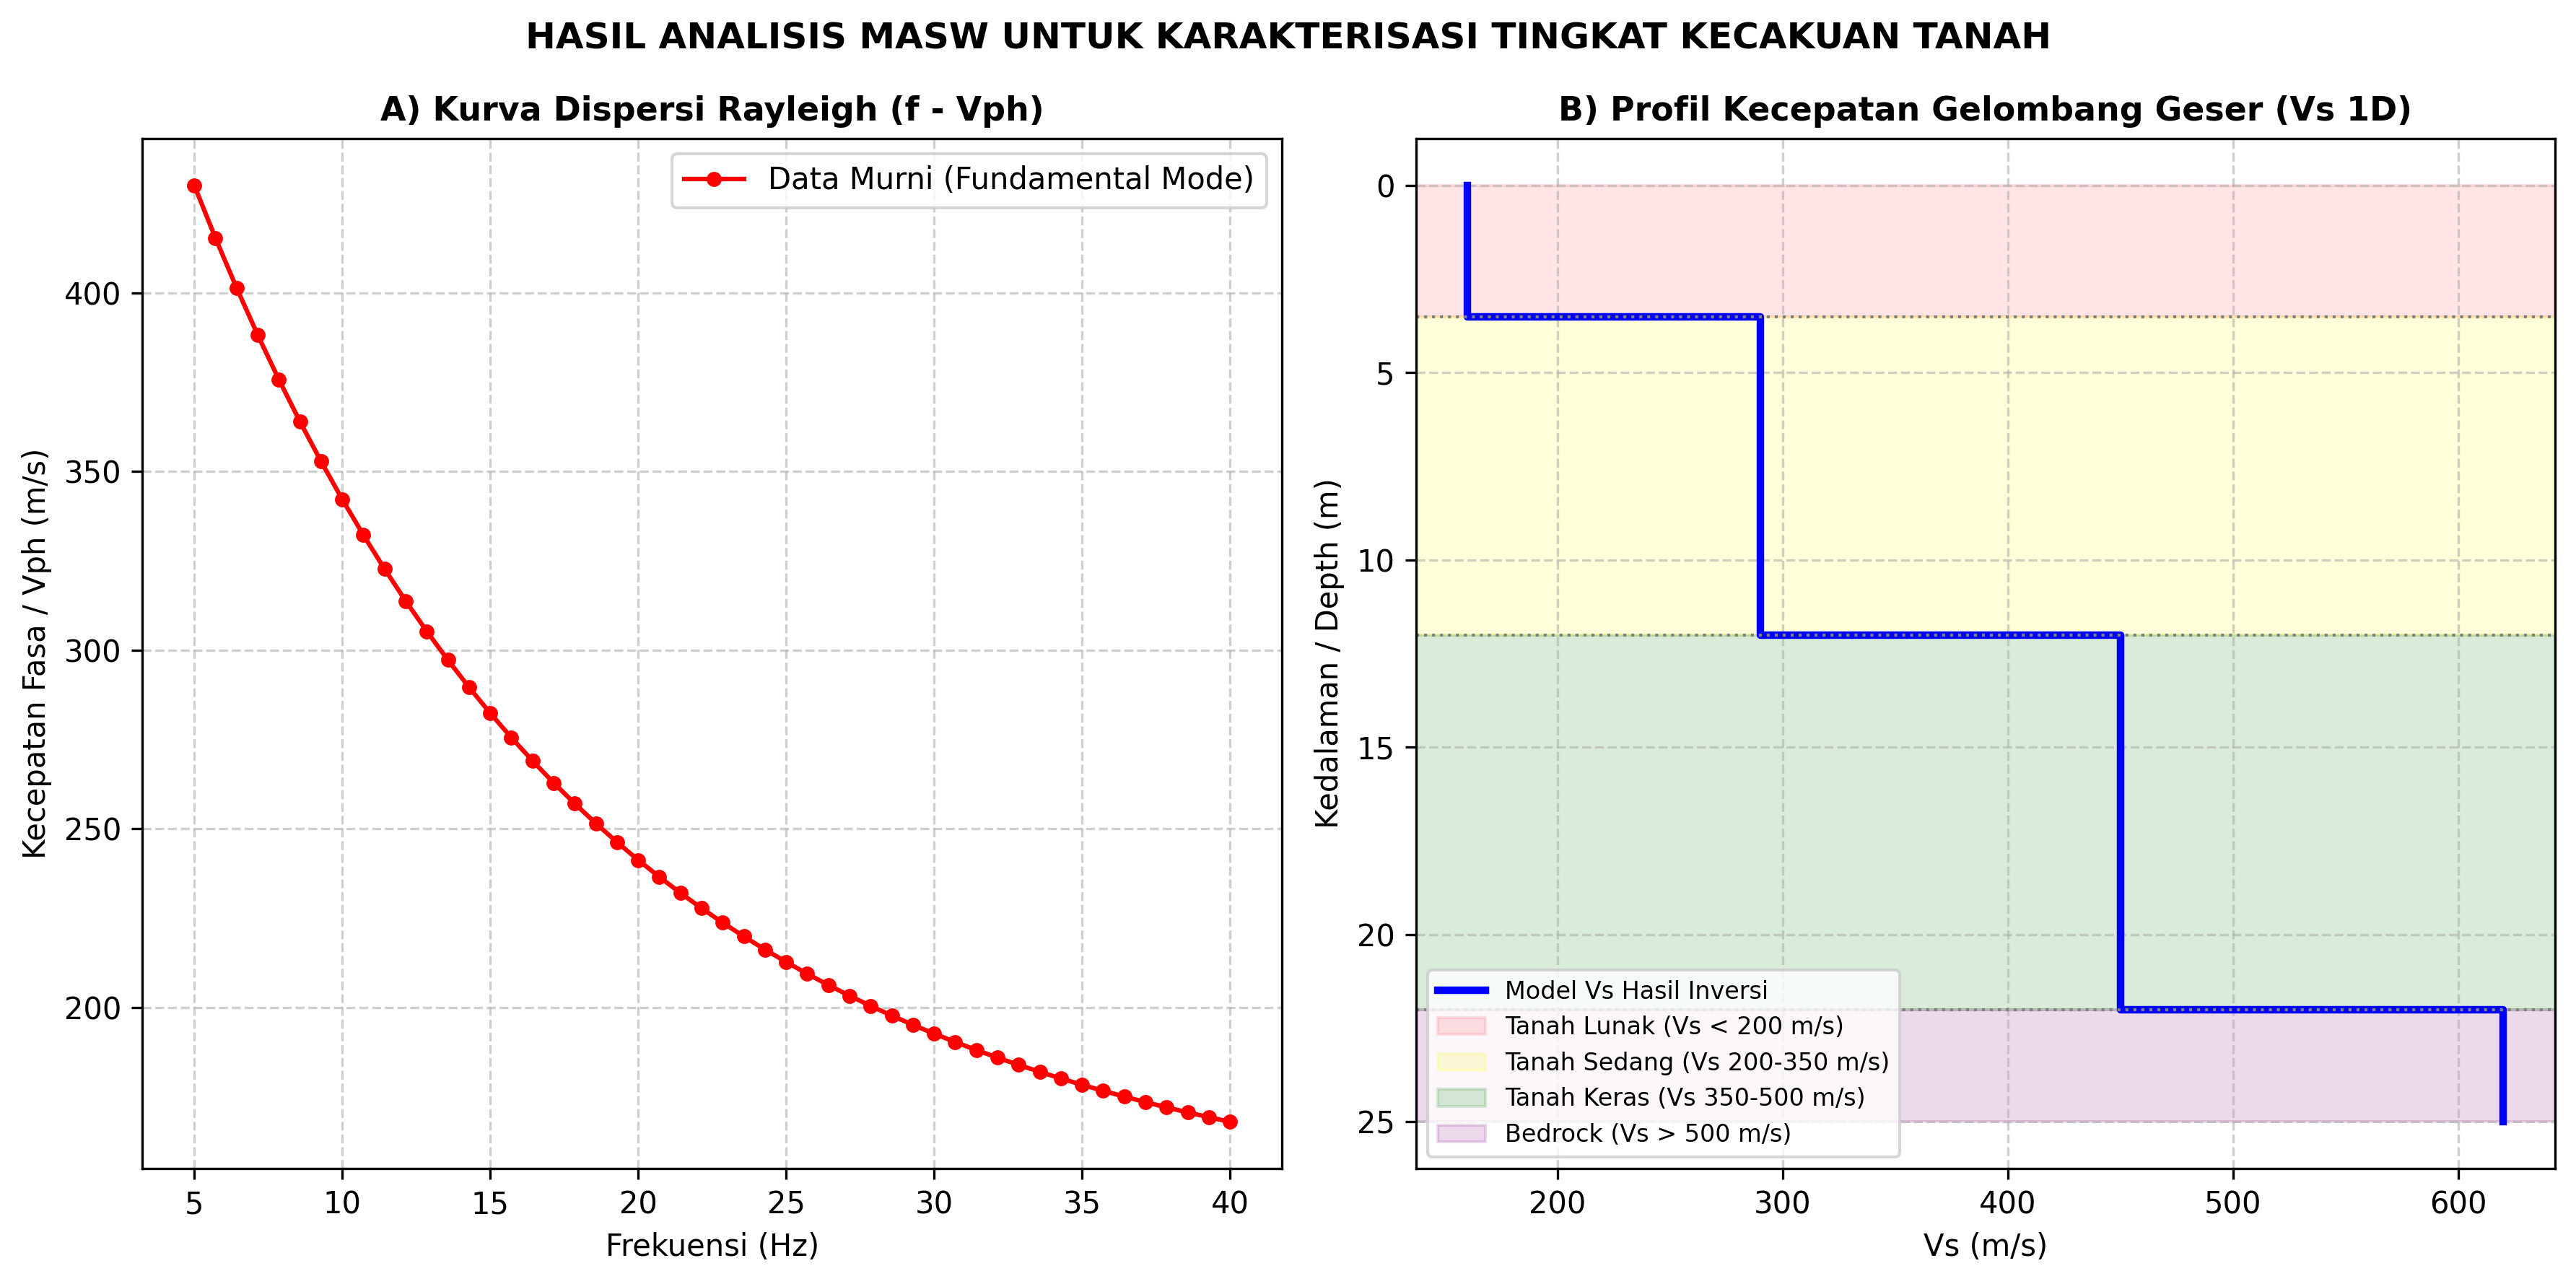

In [11]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Data Sintesis Kurva Dispersi (Frekuensi vs Kecepatan Fasa)
freq = np.linspace(5, 40, 50)
v_phase = 130 + 350 * np.exp(-freq / 12) + 80 * np.exp(-freq / 35)

# 2. Profil Vs Hasil Inversi (Kedalaman vs Vs)
depth_profile = np.array([0, 3.5, 3.5, 12.0, 12.0, 22.0, 22.0, 25.0])
vs_profile = np.array([160, 160, 290, 290, 450, 450, 620, 620])

# 3. Plotting Dual Panel
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6), dpi=300)

# Panel A: Kurva Dispersi
ax1.plot(freq, v_phase, 'ro-', linewidth=1.5, markersize=4, label='Data Murni (Fundamental Mode)')
ax1.set_title('A) Kurva Dispersi Rayleigh (f - Vph)', fontsize=11, fontweight='bold')
ax1.set_xlabel('Frekuensi (Hz)', fontsize=10)
ax1.set_ylabel('Kecepatan Fasa / Vph (m/s)', fontsize=10)
ax1.grid(True, linestyle='--', alpha=0.6)
ax1.legend()

# Panel B: Profil Vs vs Kedalaman
ax2.plot(vs_profile, depth_profile, 'b-', linewidth=2.5, label='Model Vs Hasil Inversi')
ax2.axhline(y=3.5, color='gray', linestyle=':', linewidth=1)
ax2.axhline(y=12.0, color='gray', linestyle=':', linewidth=1)
ax2.axhline(y=22.0, color='gray', linestyle=':', linewidth=1)

# Arsir Zona Litologi
ax2.axhspan(0, 3.5, color='red', alpha=0.1, label='Tanah Lunak (Vs < 200 m/s)')
ax2.axhspan(3.5, 12.0, color='yellow', alpha=0.15, label='Tanah Sedang (Vs 200-350 m/s)')
ax2.axhspan(12.0, 22.0, color='green', alpha=0.15, label='Tanah Keras (Vs 350-500 m/s)')
ax2.axhspan(22.0, 25.0, color='purple', alpha=0.15, label='Bedrock (Vs > 500 m/s)')

ax2.set_title('B) Profil Kecepatan Gelombang Geser (Vs 1D)', fontsize=11, fontweight='bold')
ax2.set_xlabel('Vs (m/s)', fontsize=10)
ax2.set_ylabel('Kedalaman / Depth (m)', fontsize=10)
ax2.invert_yaxis()  # Kedalaman bertambah ke bawah
ax2.grid(True, linestyle='--', alpha=0.6)
ax2.legend(loc='lower left', fontsize=8)

plt.suptitle('HASIL ANALISIS MASW UNTUK KARAKTERISASI TINGKAT KECAKUAN TANAH', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('masw_analysis_result.png', dpi=300)
plt.show()

# **4. STUDI KASUS GRAVITASI UNTUK IDENTIFIKASI STRUKTUR GEOLOGI**

### **Role**

Anda berperan sebagai seorang **Geophysicist senior** yang memiliki keahlian dalam metode gravitasi, pengolahan data medan gravitasi, analisis anomali Bouguer, pemisahan anomali regional dan residual, serta interpretasi struktur geologi bawah permukaan berdasarkan kontras densitas batuan.

### **Task**

Lakukan analisis data gravitasi untuk mengidentifikasi variasi densitas batuan dan memperkirakan kemungkinan struktur geologi bawah permukaan. Analisis harus dilakukan dengan menginterpretasikan pola anomali gravitasi, membandingkan anomali regional dan residual, serta menghubungkan pola tersebut dengan kondisi geologi daerah penelitian. Tujuan akhirnya adalah memperoleh model konseptual mengenai kondisi bawah permukaan berdasarkan data gravitasi.

### **Context**

Survei gravitasi dilakukan pada suatu wilayah yang memiliki kondisi geologi kompleks dan diduga memiliki struktur bawah permukaan yang belum teridentifikasi secara jelas. Data hasil pengukuran telah melalui tahapan koreksi gravitasi sehingga diperoleh Complete Bouguer Anomaly. Selanjutnya dilakukan pemisahan anomali regional dan residual untuk membantu mengidentifikasi sumber anomali yang bersifat regional maupun lokal.

### **Input**

Data yang tersedia meliputi koordinat titik pengukuran, elevasi, observed gravity, Free-Air Anomaly, Bouguer Anomaly, Complete Bouguer Anomaly, peta anomali gravitasi, data topografi, informasi geologi regional, serta hasil pemisahan anomali regional dan residual. Gunakan data geologi sebagai informasi pendukung untuk mengontrol interpretasi geofisika dan jangan membuat data densitas atau parameter lain yang tidak tersedia.

### **Constraints**

Jangan secara langsung menginterpretasikan anomali gravitasi positif atau negatif sebagai struktur geologi tertentu tanpa mempertimbangkan kontras densitas dan kondisi geologi. Pertimbangkan kemungkinan bahwa satu pola anomali dapat disebabkan oleh lebih dari satu konfigurasi bawah permukaan karena metode gravitasi memiliki ambiguitas yang tinggi. Jangan menentukan kedalaman atau bentuk struktur secara pasti jika tidak didukung oleh pemodelan atau data tambahan. Jelaskan seluruh asumsi dan ketidakpastian yang digunakan dalam interpretasi.

### **Output**

Hasil analisis harus mencakup prinsip metode gravitasi, tahapan pengolahan data, interpretasi Complete Bouguer Anomaly, analisis anomali regional dan residual, identifikasi pola anomali, interpretasi kemungkinan struktur bawah permukaan, model konseptual geologi, ketidakpastian interpretasi, rekomendasi metode geofisika tambahan, serta kesimpulan. Sajikan hasil secara objektif, sistematis, dan berdasarkan prinsip dasar geofisika.

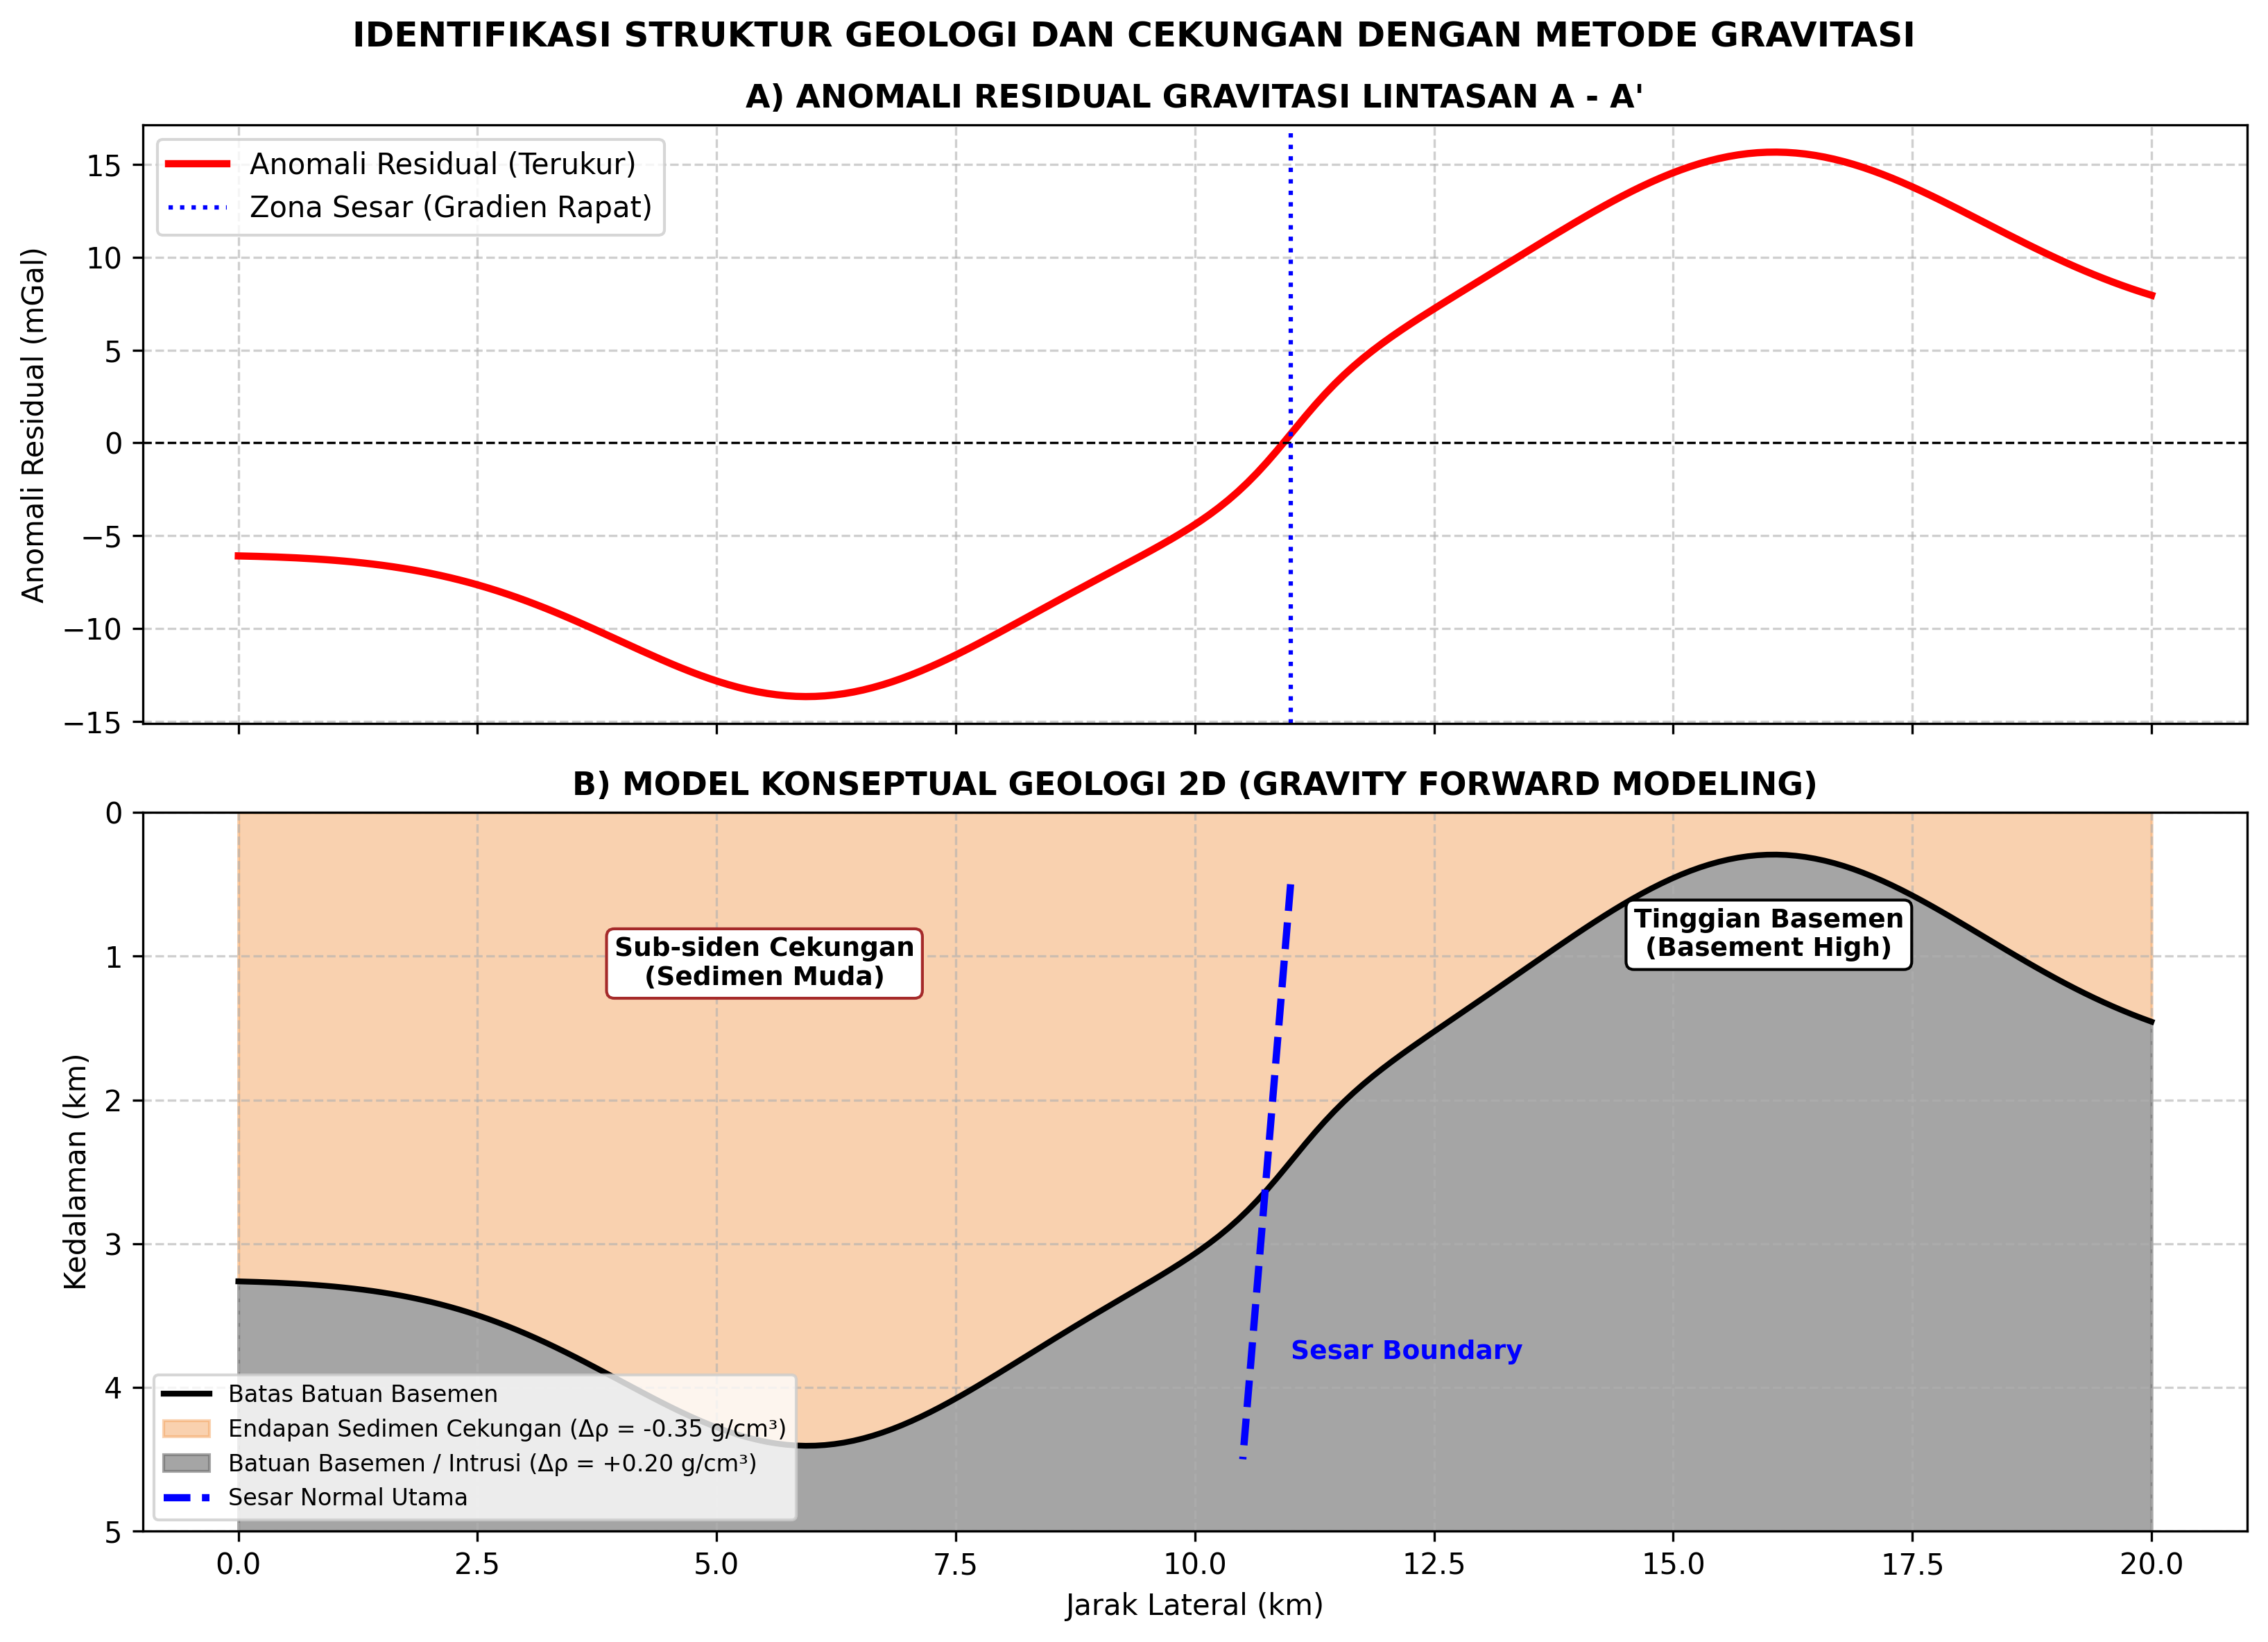

In [12]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Grid Data Sintetis Lintasan A-A' (Jarak 0 - 20 km)
x = np.linspace(0, 20, 200) # Jarak lateral dalam km

# 2. Pemodelan Respon Anomali Residual (mGal)
# Terdiri dari respon Cekungan (Low) + Basemen High + Efek Sesar (Gradien)
basin_effect = -8 * np.exp(-((x - 6)**2) / 8)
basement_high = 10 * np.exp(-((x - 16)**2) / 10)
fault_gradient = 4 * np.arctan((x - 11) / 0.8)

gravity_residual = basin_effect + basement_high + fault_gradient

# 3. Model Geometri Bawah Permukaan 2D (Kedalaman km)
# Topografi Basemen
basement_depth = 2.5 + 1.2 * np.exp(-((x - 6)**2) / 8) - 1.5 * np.exp(-((x - 16)**2) / 10) - 0.5 * np.arctan((x - 11) / 0.8)

# 4. Canvas Plots Dual Panel
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 8), sharex=True, dpi=300, gridspec_kw={'height_ratios': [1, 1.2]})

# Panel Atas: Kurva Anomali Residual Gravitasi
ax1.plot(x, gravity_residual, 'r-', linewidth=2.5, label='Anomali Residual (Terukur)')
ax1.axhline(0, color='black', linestyle='--', linewidth=0.8)
ax1.axvline(11, color='blue', linestyle=':', label='Zona Sesar (Gradien Rapat)')

ax1.set_title('A) ANOMALI RESIDUAL GRAVITASI LINTASAN A - A\'', fontsize=11, fontweight='bold')
ax1.set_ylabel('Anomali Residual (mGal)', fontsize=10)
ax1.grid(True, linestyle='--', alpha=0.6)
ax1.legend(loc='upper left')

# Panel Bawah: Penampang Geologi Bawah Permukaan 2D
ax2.plot(x, basement_depth, 'k-', linewidth=2, label='Batas Batuan Basemen')
ax2.fill_between(x, 0, basement_depth, color='sandybrown', alpha=0.5, label='Endapan Sedimen Cekungan (\u0394\u03c1 = -0.35 g/cm\u00b3)')
ax2.fill_between(x, basement_depth, 5, color='dimgray', alpha=0.6, label='Batuan Basemen / Intrusi (\u0394\u03c1 = +0.20 g/cm\u00b3)')

# Tambah Garis Sesar
ax2.plot([11, 10.5], [0.5, 4.5], 'b--', linewidth=2.5, label='Sesar Normal Utama')

# Annotasi Zona
ax2.text(5.5, 1.2, 'Sub-siden Cekungan\n(Sedimen Muda)', fontsize=9, ha='center', fontweight='bold', bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="brown"))
ax2.text(16, 1.0, 'Tinggian Basemen\n(Basement High)', fontsize=9, ha='center', fontweight='bold', bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="black"))
ax2.text(11, 3.8, 'Sesar Boundary', fontsize=9, color='blue', fontweight='bold')

ax2.set_title('B) MODEL KONSEPTUAL GEOLOGI 2D (GRAVITY FORWARD MODELING)', fontsize=11, fontweight='bold')
ax2.set_xlabel('Jarak Lateral (km)', fontsize=10)
ax2.set_ylabel('Kedalaman (km)', fontsize=10)
ax2.set_ylim(0, 5)
ax2.invert_yaxis() # Kedalaman mengarah ke bawah
ax2.grid(True, linestyle='--', alpha=0.6)
ax2.legend(loc='lower left', fontsize=8)

plt.suptitle('IDENTIFIKASI STRUKTUR GEOLOGI DAN CEKUNGAN DENGAN METODE GRAVITASI', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('gravity_interpretation_result.png', dpi=300)
plt.show()

# **5. STUDI KASUS SEISMIC ATTRIBUTE UNTUK IDENTIFIKASI ZONA PROSPEK HIDROKARBON**

### **Role**

Anda berperan sebagai seorang **Senior Exploration Geophysicist** yang memiliki keahlian dalam interpretasi seismic reflection 3D, seismic attributes, interpretasi struktur dan stratigrafi, serta eksplorasi hidrokarbon. Anda memahami prinsip dan keterbatasan berbagai seismic attributes serta mampu mengintegrasikan informasi seismic dengan well log dan data geologi.

### **Task**

Lakukan analisis seismic attributes untuk mengidentifikasi karakteristik reflektor, struktur geologi, dan zona yang memiliki karakteristik yang konsisten dengan reservoir hidrokarbon. Analisis harus dilakukan dengan membandingkan beberapa seismic attributes dan mengintegrasikan hasilnya dengan data well log sehingga dapat diketahui hubungan antara respon seismik dengan karakteristik reservoir pada lokasi sumur.

### **Context**

Sebuah wilayah eksplorasi migas memiliki data seismic 3D dan beberapa sumur eksplorasi. Interpretasi awal menunjukkan adanya struktur antiklin dan beberapa sesar yang berpotensi membentuk perangkap hidrokarbon. Untuk meningkatkan kualitas interpretasi, beberapa seismic attributes seperti RMS amplitude, envelope, instantaneous frequency, sweetness, dan variance atau coherence digunakan untuk melihat variasi karakteristik reflektor dan struktur bawah permukaan. Hasil analisis attribute kemudian akan dikorelasikan dengan data well log untuk mengevaluasi konsistensi antara respon seismik dan kondisi reservoir.

### **Input**

Data yang tersedia meliputi seismic 3D, RMS amplitude, envelope, instantaneous frequency, sweetness, variance atau coherence, Gamma Ray, resistivity, density, neutron porosity, sonic log, well tops, serta data checkshot atau VSP apabila tersedia. Data tersebut digunakan untuk menganalisis karakteristik reflektor, mengidentifikasi struktur, dan mengevaluasi hubungan antara seismic attribute dengan kondisi reservoir pada lokasi sumur.

### **Constraints**

Jangan menentukan suatu zona sebagai reservoir hidrokarbon hanya berdasarkan satu seismic attribute karena setiap attribute memiliki sensitivitas dan keterbatasan yang berbeda. Interpretasi harus dilakukan dengan mengintegrasikan beberapa attribute, data well log, dan informasi geologi. Bedakan antara anomali seismic, indikasi reservoir, dan bukti keberadaan hidrokarbon. Pertimbangkan pengaruh tuning effect, noise, resolusi vertikal, kualitas data, dan keterbatasan jumlah sumur. Jangan membuat data yang tidak tersedia dan jangan menyatakan suatu interpretasi sebagai kepastian apabila hanya didukung oleh indikasi tidak langsung.

### **Output**

Berikan hasil analisis yang mencakup tujuan interpretasi, karakteristik data seismic, prinsip dan fungsi masing-masing seismic attribute, interpretasi horizon, identifikasi sesar, analisis RMS amplitude, envelope, instantaneous frequency, sweetness, dan variance atau coherence, korelasi hasil attribute dengan well log, identifikasi zona prospek, pembahasan ketidakpastian, rekomendasi analisis lanjutan, dan kesimpulan. Gunakan bahasa akademik yang formal, objektif, dan mudah dipahami serta pastikan setiap kesimpulan memiliki dasar dari data yang tersedia.


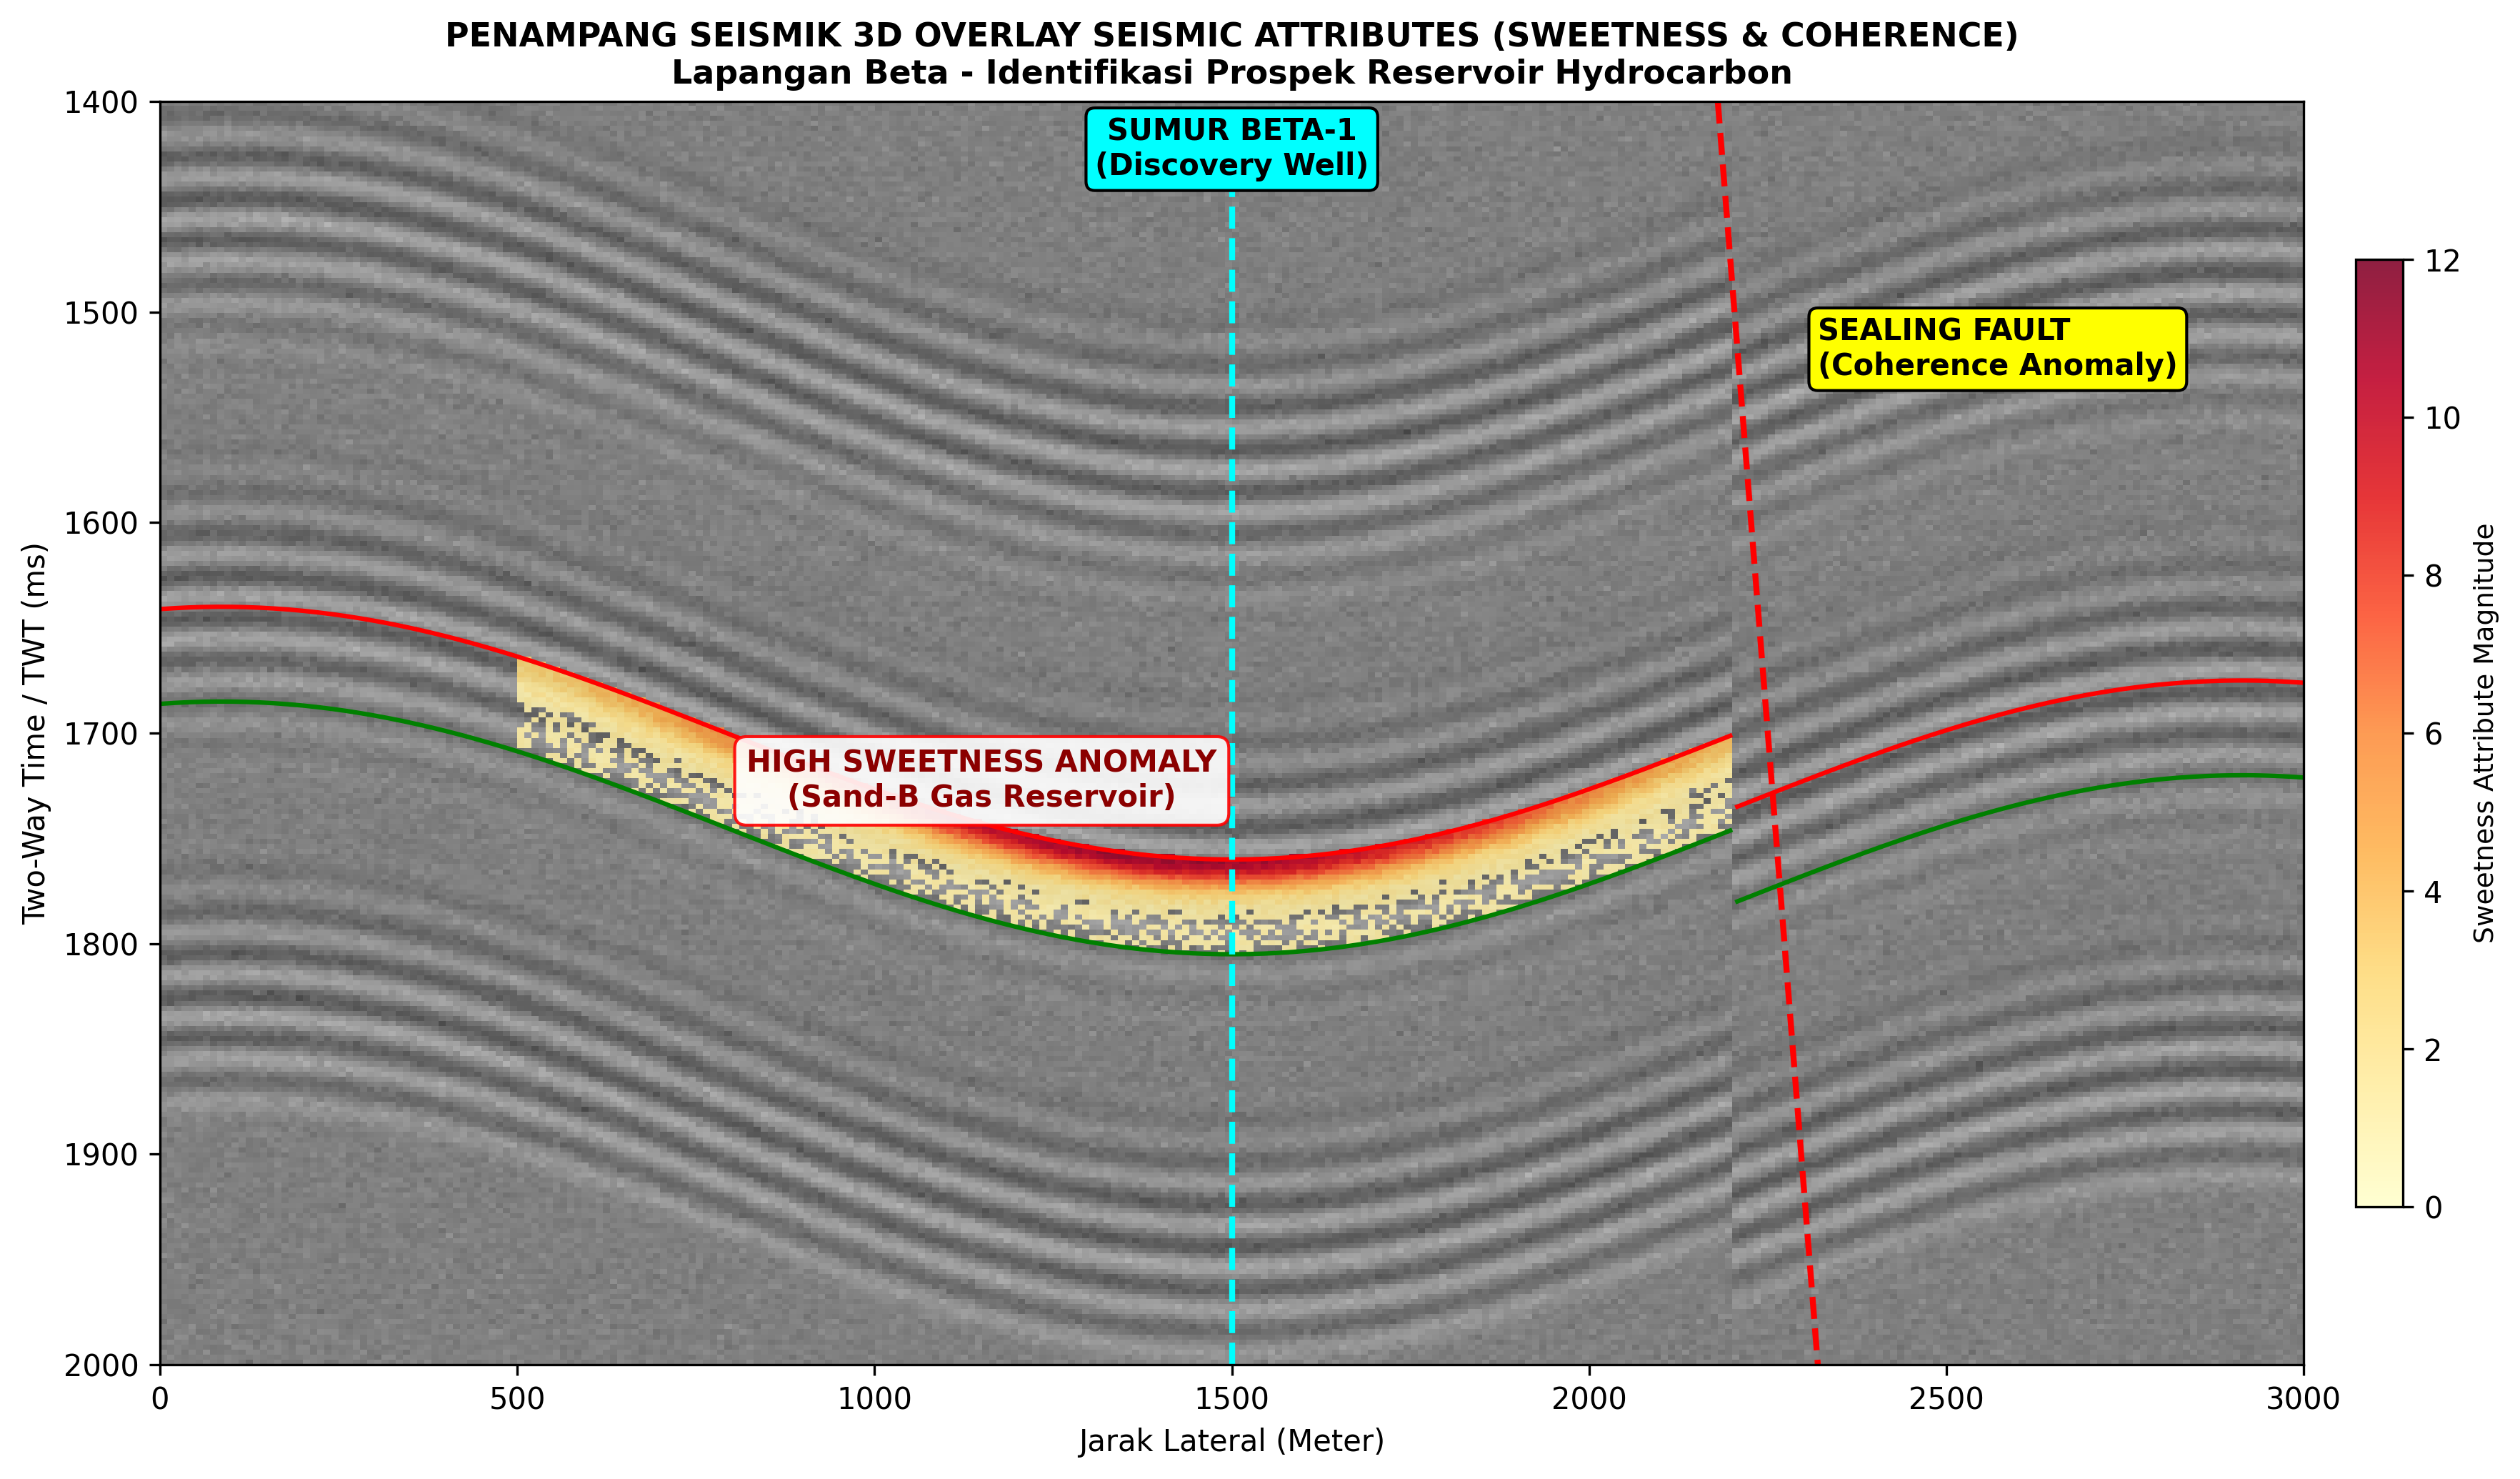

In [14]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Bikin Grid Seismik Sintetis (300 titik lateral x 250 titik waktu)
x = np.linspace(0, 3000, 300)          # Jarak Lateral (0 - 3000 meter)
t = np.linspace(1400, 2000, 250)       # Two-Way Time / TWT (1400 - 2000 ms)
X, T = np.meshgrid(x, t)

# 2. Pemodelan Struktur Antiklin & Sesar (Faulting)
# Horizon Utama (Top Sand-B) mengikuti bentuk lipatan antiklin
top_sand_twt = 1700 + 60 * np.cos((X - 1500) / 450)

# Sesar Normal (Fault Displacement) pada X = 2200m - 2300m
fault_offset = np.where(X > 2200, 35, 0)
top_sand_twt += fault_offset

# Base Sand-B / OWC
base_sand_twt = top_sand_twt + 45

# 3. Membuat Reflektor Gelombang Seismik Realistis (Multi-Layer Wiggles)
seismic_amplitude = np.zeros_like(X)

# Membuat serangkaian horizon background di atas dan di bawah target
for offset in np.arange(-250, 250, 20):
    layer_twt = top_sand_twt + offset
    # Ricker Wavelet sintesis
    wavelet = np.sin((T - layer_twt) / 6) * np.exp(-((T - layer_twt)**2) / 80)
    # Tambah variasi amplitudo acak tiap lapisan
    seismic_amplitude += wavelet * (0.5 + 0.5 * np.cos(offset / 30))

# Tambahkan random noise agar tekstur seismik terlihat sangat alami
np.random.seed(42)
seismic_amplitude += np.random.normal(0, 0.08, seismic_amplitude.shape)

# 4. Pemodelan Atribut Sweetness (Mengikuti Geometri Struktur Sand-B)
sweetness_attr = np.zeros_like(X)

# Masking zona reservoir: Di antara Top Sand-B dan Base Sand-B, serta terisolasi di puncak antiklin (X: 500m - 2200m)
reservoir_mask = (T >= top_sand_twt) & (T <= base_sand_twt) & (X >= 500) & (X <= 2200)

# Isi nilai Sweetness (Tinggi pada puncak antiklin dekat sumur Beta-1)
sweetness_values = 10.5 * np.exp(-((X - 1400)**2) / (2 * 500**2)) * np.exp(-((T - top_sand_twt)**2) / 200)
sweetness_attr[reservoir_mask] = sweetness_values[reservoir_mask] + np.random.uniform(0.5, 1.5, np.sum(reservoir_mask))

# Masking warna netral untuk background (biar transparan saat overlay)
sweetness_attr_masked = np.ma.masked_where(sweetness_attr < 1.0, sweetness_attr)

# 5. Canvas Plot Visualisasi
fig, ax = plt.subplots(figsize=(13, 7), dpi=300)

# Plot Penampang Seismik Gray Scale (Gelombang Seismik Nyata)
ax.imshow(seismic_amplitude, extent=[0, 3000, 2000, 1400], cmap='gray', aspect='auto', vmin=-1.8, vmax=1.8)

# Overlay Atribut Sweetness (Color Map YlOrRd)
im_sweet = ax.imshow(sweetness_attr_masked, extent=[0, 3000, 2000, 1400], cmap='YlOrRd', aspect='auto', vmin=0, vmax=12, alpha=0.88)

# Plot Garis Horizon (Top & Base Sand-B)
ax.plot(x[x <= 2200], top_sand_twt[0, x <= 2200], 'r-', linewidth=1.5, label='Top Sand-B')
ax.plot(x[x > 2200], top_sand_twt[0, x > 2200], 'r-', linewidth=1.5)
ax.plot(x[x <= 2200], base_sand_twt[0, x <= 2200], 'g-', linewidth=1.5, label='Base Sand-B / OWC')
ax.plot(x[x > 2200], base_sand_twt[0, x > 2200], 'g-', linewidth=1.5)

# Plot Garis Patahan Sesar (Sealing Fault)
ax.plot([2180, 2320], [1400, 2000], 'r--', linewidth=2.0, label='Sealing Fault (Coherence)')

# Plot Sumur Beta-1
ax.axvline(x=1500, color='cyan', linestyle='--', linewidth=2, label='Sumur Beta-1')

# Annotasi Teks
ax.text(1500, 1435, 'SUMUR BETA-1\n(Discovery Well)', color='black', fontweight='bold', ha='center', bbox=dict(boxstyle='round,pad=0.3', fc='cyan', ec='black'))
ax.text(1150, 1735, 'HIGH SWEETNESS ANOMALY\n(Sand-B Gas Reservoir)', color='darkred', fontweight='bold', ha='center', bbox=dict(boxstyle='round,pad=0.4', fc='white', ec='red', alpha=0.9))
ax.text(2320, 1530, 'SEALING FAULT\n(Coherence Anomaly)', color='black', fontweight='bold', bbox=dict(boxstyle='round,pad=0.3', fc='yellow', ec='black'))

# Setup Label dan Judul Sumbu
ax.set_title('PENAMPANG SEISMIK 3D OVERLAY SEISMIC ATTRIBUTES (SWEETNESS & COHERENCE)\nLapangan Beta - Identifikasi Prospek Reservoir Hydrocarbon', fontsize=11, fontweight='bold')
ax.set_xlabel('Jarak Lateral (Meter)', fontsize=10)
ax.set_ylabel('Two-Way Time / TWT (ms)', fontsize=10)
ax.set_xlim(0, 3000)
ax.set_ylim(2000, 1400) # Reversi sumbu Y agar waktu bertambah ke bawah

# Colorbar Atribut Sweetness
cbar = fig.colorbar(im_sweet, ax=ax, orientation='vertical', shrink=0.75, pad=0.02)
cbar.set_label('Sweetness Attribute Magnitude', fontsize=9)

plt.tight_layout()
plt.savefig('seismic_attribute_professional.png', dpi=300)
plt.show()